# Fintech Customer Segmentation & High-Value Customer Identification

Goal: identify a bank's most valuable and highest-potential customers by looking at **more than account balance**: income, spending, investments, credit, digital engagement and relationship depth. Then segment them and recommend an action for each.

**Pipeline:** Load data → Data quality checks → EDA → Feature engineering → Customer Value Score → Value-vs-Potential matrix → K-Means clustering → Compare with bank segments → Prioritise opportunities → Recommend actions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## 1. Load the data
The Excel workbook has 5 sheets. `Customer_360` holds one row per customer (10,000 customers, 26 columns).

In [3]:
file_path = "data/High_Value_Customer_Identification_Final.xlsx"

excel_file = pd.ExcelFile(file_path)

print(excel_file.sheet_names)

['Customer_360', 'Segment_Profile', 'Value_Contribution', 'Scoring_Framework', 'Recommendations']


In [4]:
df = pd.read_excel(file_path, sheet_name="Customer_360")

df.head()


,customer_id,age,gender,annual_income,avg_balance,monthly_transactions,monthly_spend,credit_score,loan_amount,investment_value,...,financial_strength_score,transaction_behaviour_score,spending_behaviour_score,credit_profile_score,customer_engagement_score,relationship_value_score,future_potential_score,cluster,segment,recommended_product
0,C100001,59,F,786034,1277297,141,45778,782,0,1381177,...,7.640658,54.811715,7.139007,36.529680,35.593220,77.083333,42.025004,1,Silver,Digital Banking Engagement
1,C100002,49,M,1014139,2372146,46,62362,792,339582,56438,...,8.824038,15.062762,9.807326,48.361524,100.000000,85.416667,66.763509,3,Gold,Premium Credit Card / Rewards
2,C100003,35,F,816009,1248593,208,46575,657,403519,1463822,...,7.794932,82.845188,7.267242,34.963348,50.847458,52.083333,25.030140,1,Silver,Cross-sell Additional Banking Products
3,C100004,63,M,1795029,3872018,72,154180,641,0,766337,...,16.138676,25.941423,24.580581,20.433790,76.271186,50.000000,48.967799,2,Premium,Wealth Management / Investment Advisory
4,C100005,28,F,1272864,2762969,60,14311,786,304109,801798,...,11.854696,20.920502,2.076056,46.559876,3.389831,37.500000,13.624094,0,Standard,Cross-sell Additional Banking Products


In [5]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Shape: (10000, 26)

Columns:
['customer_id', 'age', 'gender', 'annual_income', 'avg_balance', 'monthly_transactions', 'monthly_spend', 'credit_score', 'loan_amount', 'investment_value', 'products_used', 'mobile_app_logins', 'years_with_bank', 'complaints', 'age_group', 'customer_value_score', 'financial_strength_score', 'transaction_behaviour_score', 'spending_behaviour_score', 'credit_profile_score', 'customer_engagement_score', 'relationship_value_score', 'future_potential_score', 'cluster', 'segment', 'recommended_product']

Data Types:
customer_id                     object
age                              int64
gender                          object
annual_income                    int64
avg_balance                      int64
monthly_transactions             int64
monthly_spend                    int64
credit_score                     int64
loan_amount                      int64
investment_value                 int64
products_used                    int64
mobile_app_logins        

## 2. Data quality checks
Check for missing values, duplicate rows and duplicate customer IDs before any analysis.

In [6]:
missing = df.isnull().sum()

missing[missing > 0]

,0


In [7]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate Customer IDs:", df["customer_id"].duplicated().sum())

Duplicate rows: 0
Duplicate Customer IDs: 0


## 3. Exploratory Data Analysis (EDA)
Summary statistics, segment distribution, financial and behavioural variables by segment, and correlations.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,10000.0,4.562040e+01,1.434349e+01,21.000000,33.000000,46.000000,5.800000e+01,7.000000e+01
annual_income,10000.0,9.623842e+05,6.350783e+05,76033.000000,537578.000000,805811.000000,1.207945e+06,1.175533e+07
avg_balance,10000.0,1.244100e+06,1.123433e+06,21959.000000,475071.500000,945131.000000,1.649701e+06,1.297110e+07
monthly_transactions,10000.0,1.295903e+02,6.966799e+01,10.000000,69.000000,129.000000,1.900000e+02,2.490000e+02
monthly_spend,10000.0,5.247785e+04,4.674878e+04,1408.000000,21182.250000,39413.000000,6.835000e+04,6.229230e+05
credit_score,10000.0,7.195854e+02,6.913779e+01,462.000000,673.000000,720.000000,7.670000e+02,9.000000e+02
loan_amount,10000.0,3.344725e+05,2.908523e+05,0.000000,62466.500000,295975.000000,5.264145e+05,1.588273e+06
investment_value,10000.0,9.711874e+05,9.352681e+05,317.000000,330310.000000,717492.000000,1.313072e+06,1.931721e+07
products_used,10000.0,4.019500e+00,1.984821e+00,1.000000,2.000000,4.000000,6.000000e+00,7.000000e+00
mobile_app_logins,10000.0,2.944580e+01,1.744709e+01,0.000000,14.000000,29.000000,4.500000e+01,5.900000e+01


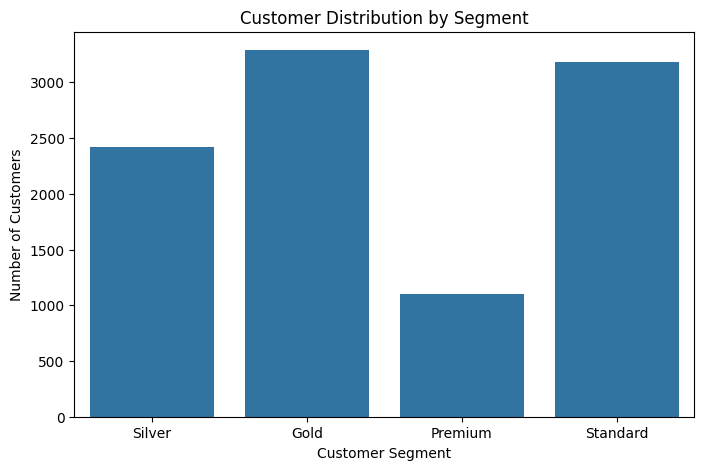

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="segment")

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.show()

In [10]:
segment_summary = df.groupby("segment").agg(
    customers=("customer_id", "count"),
    avg_income=("annual_income", "mean"),
    avg_balance=("avg_balance", "mean"),
    avg_spend=("monthly_spend", "mean"),
    avg_investment=("investment_value", "mean"),
    avg_credit_score=("credit_score", "mean"),
    avg_products=("products_used", "mean"),
    avg_app_logins=("mobile_app_logins", "mean"),
    avg_complaints=("complaints", "mean")
).round(2)

segment_summary

,customers,avg_income,avg_balance,avg_spend,avg_investment,avg_credit_score,avg_products,avg_app_logins,avg_complaints
segment,,,,,,,,,
Gold,3290,812107.89,1008157.05,40563.57,806595.16,722.10,4.67,46.92,0.52
Premium,1104,2149197.14,3140273.19,144924.30,2383512.99,718.31,4.04,31.65,0.52
Silver,2420,816932.60,1009067.16,40913.24,795880.95,715.51,5.43,15.88,0.50
Standard,3186,816797.47,1009216.03,41531.03,784917.12,720.52,2.27,20.94,0.48


In [11]:
segment_distribution = (
    df["segment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

segment_distribution

,proportion
segment,
Gold,32.90
Standard,31.86
Silver,24.20
Premium,11.04


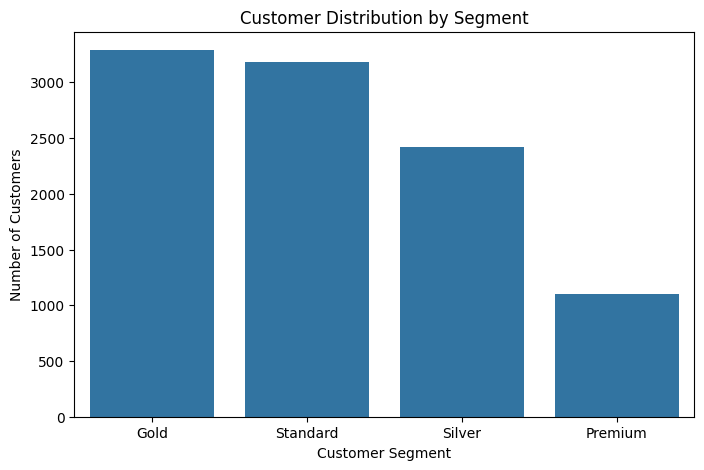

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="segment",
    order=df["segment"].value_counts().index
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.show()

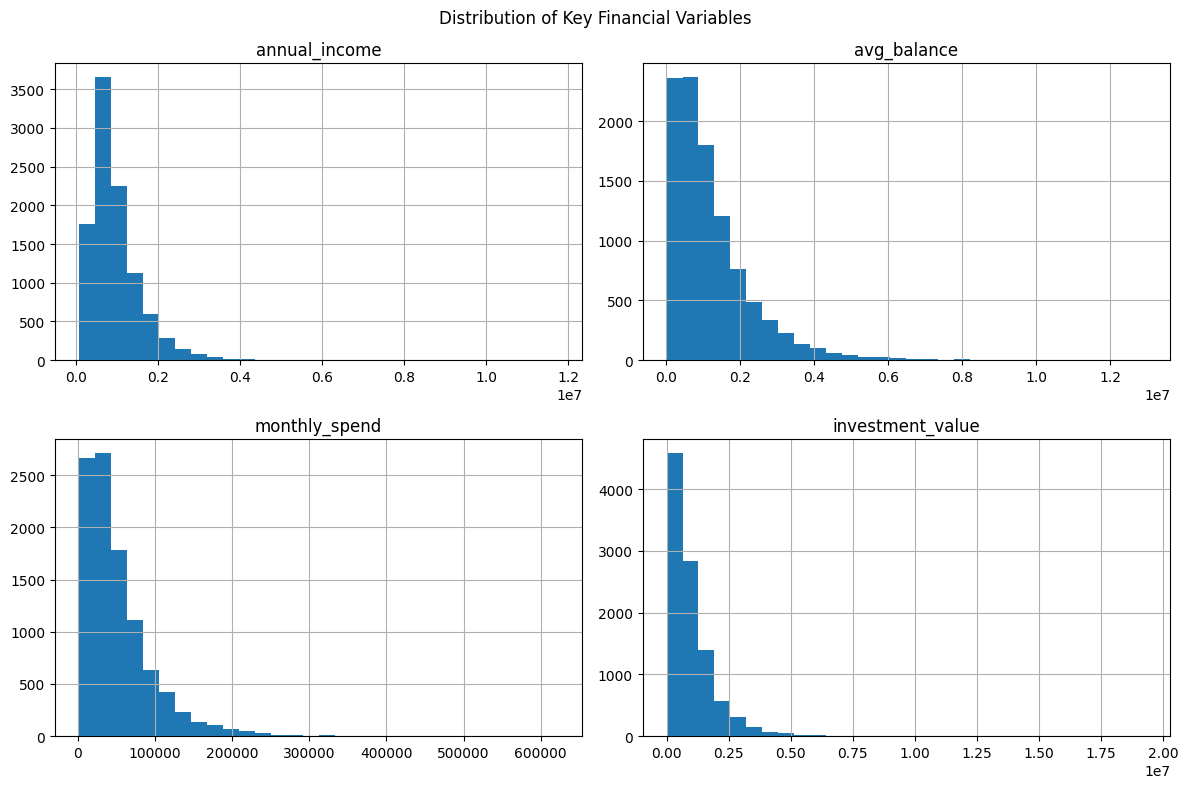

In [13]:
financial_cols = [
    "annual_income",
    "avg_balance",
    "monthly_spend",
    "investment_value"
]

df[financial_cols].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle("Distribution of Key Financial Variables")
plt.tight_layout()
plt.show()

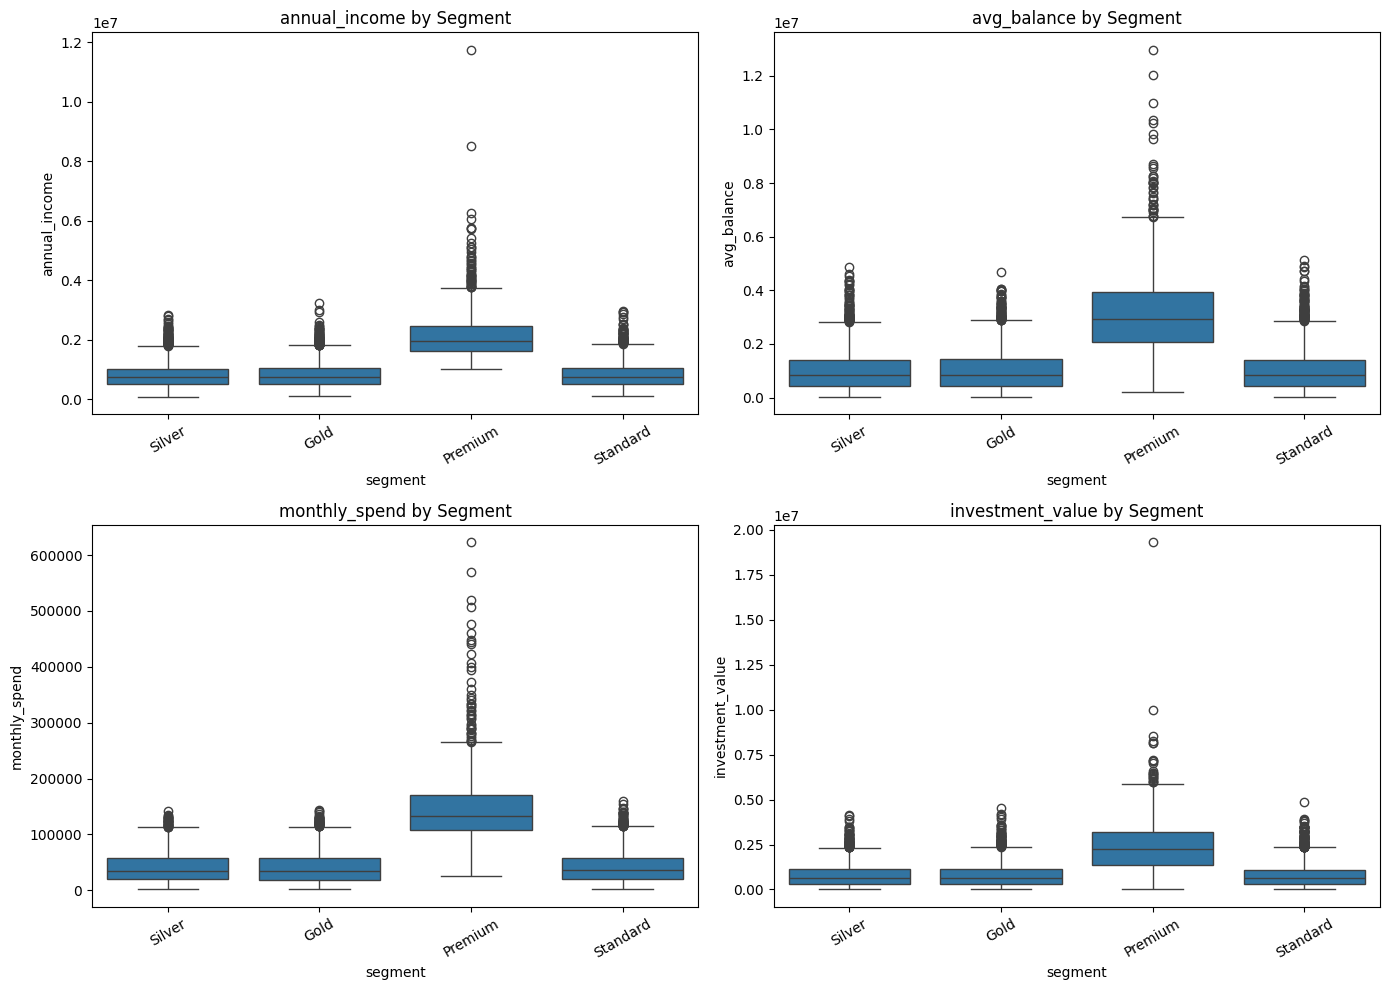

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flatten(), financial_cols):
    sns.boxplot(data=df, x="segment", y=col, ax=ax)
    ax.set_title(f"{col} by Segment")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [15]:
behavior_cols = [
    "monthly_transactions",
    "monthly_spend",
    "mobile_app_logins",
    "products_used",
    "years_with_bank",
    "complaints"
]

behavior_summary = df.groupby("segment")[behavior_cols].mean().round(2)

behavior_summary

,monthly_transactions,monthly_spend,mobile_app_logins,products_used,years_with_bank,complaints
segment,,,,,,
Gold,124.57,40563.57,46.92,4.67,12.36,0.52
Premium,130.19,144924.30,31.65,4.04,12.07,0.52
Silver,140.30,40913.24,15.88,5.43,14.80,0.50
Standard,126.43,41531.03,20.94,2.27,9.39,0.48


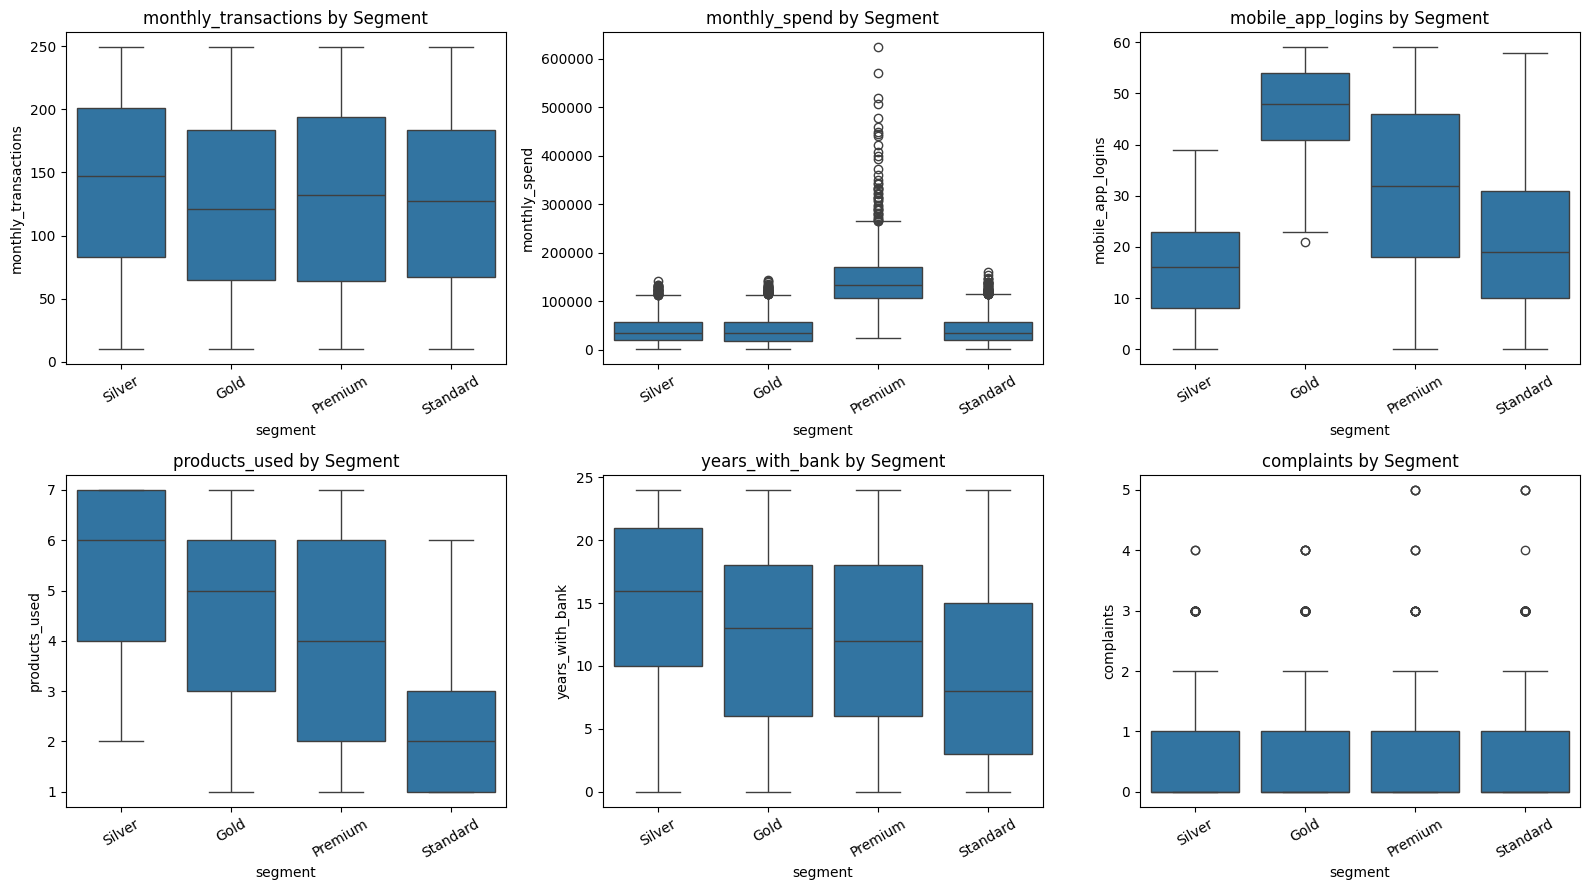

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), behavior_cols):
    sns.boxplot(
        data=df,
        x="segment",
        y=col,
        ax=ax
    )
    ax.set_title(f"{col} by Segment")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

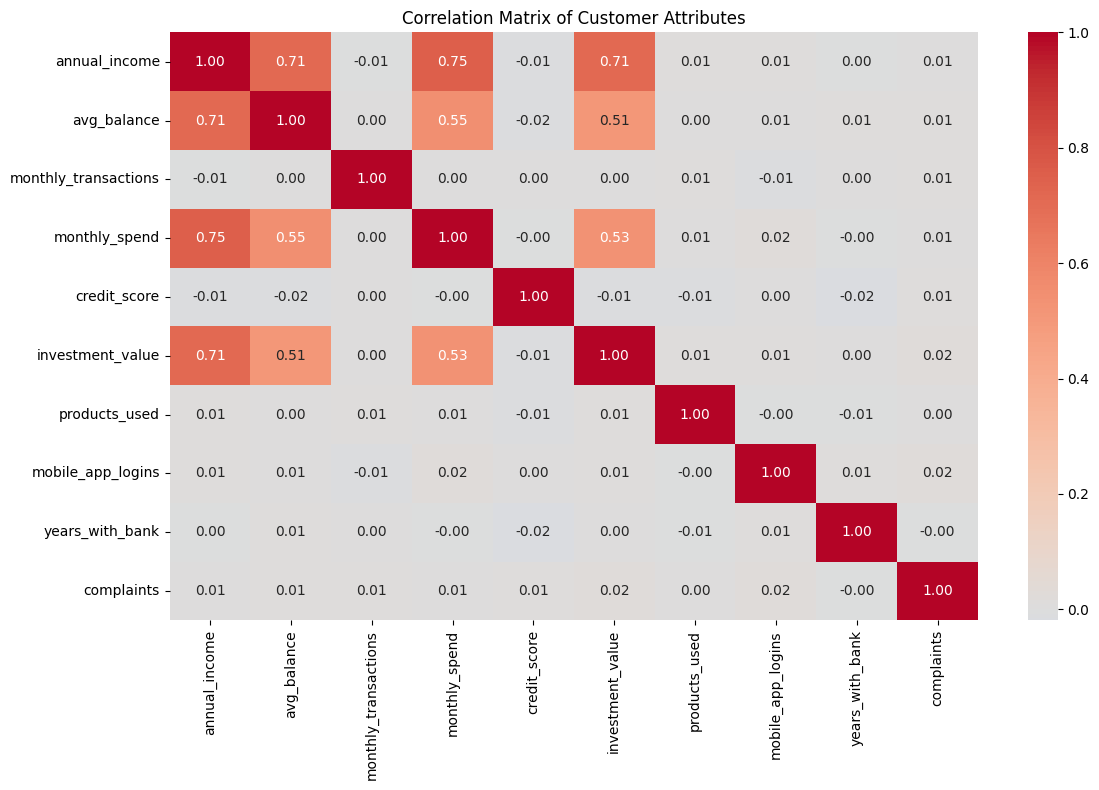

In [17]:
numeric_cols = [
    "annual_income",
    "avg_balance",
    "monthly_transactions",
    "monthly_spend",
    "credit_score",
    "investment_value",
    "products_used",
    "mobile_app_logins",
    "years_with_bank",
    "complaints"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Customer Attributes")
plt.tight_layout()
plt.show()

## 4. Feature engineering
New ratio features: spend-to-income, investment-to-balance, product penetration, spend per transaction. Then flag high-income customers who are not yet Premium.

In [20]:
df["annual_spend"] = df["monthly_spend"] * 12

df["spend_to_income_ratio"] = (
    df["annual_spend"] / df["annual_income"]
)

df["spend_to_income_ratio"].describe()

,spend_to_income_ratio
count,10000.000000
mean,0.653016
std,0.318122
min,0.100100
25%,0.377709
50%,0.652650
75%,0.931724
max,1.199785


In [21]:
df["investment_to_balance_ratio"] = (
    df["investment_value"] / df["avg_balance"]
)

df["investment_to_balance_ratio"].describe()

,investment_to_balance_ratio
count,10000.000000
mean,1.325996
std,1.811147
min,0.000346
25%,0.390305
50%,0.769786
75%,1.421310
max,19.786892


In [22]:
df["product_penetration"] = (
    df["products_used"] / df["products_used"].max()
)

df["product_penetration"].describe()

,product_penetration
count,10000.000000
mean,0.574214
std,0.283546
min,0.142857
25%,0.285714
50%,0.571429
75%,0.857143
max,1.000000


In [23]:
df["spend_per_transaction"] = (
    df["monthly_spend"] / df["monthly_transactions"]
)

df["spend_per_transaction"].describe()

,spend_per_transaction
count,10000.000000
mean,719.717415
std,1226.921730
min,6.158333
25%,167.245695
50%,341.565313
75%,743.825487
max,34075.200000


In [24]:
income_threshold = df["annual_income"].quantile(0.90)

high_income_non_premium = df[
    (df["segment"] != "Premium") &
    (df["annual_income"] >= income_threshold)
]

print("High-income non-Premium customers:",
      len(high_income_non_premium))

high_income_non_premium[
    [
        "customer_id",
        "segment",
        "annual_income",
        "avg_balance",
        "monthly_spend",
        "investment_value",
        "mobile_app_logins",
        "products_used"
    ]
].head(10)

High-income non-Premium customers: 292


,customer_id,segment,annual_income,avg_balance,monthly_spend,investment_value,mobile_app_logins,products_used
39,C100040,Silver,1956073,1367149,27115,2051375,22,6
41,C100042,Gold,2018875,2979420,53930,1844253,41,5
50,C100051,Gold,1826158,2325326,98876,45065,47,7
74,C100075,Standard,2006284,1928269,52332,1222606,19,3
85,C100086,Gold,1828063,651972,19746,280542,49,5
162,C100163,Gold,2012332,1344747,28982,3917221,47,4
227,C100228,Standard,1960270,532935,118858,1224657,19,5
276,C100277,Standard,2536954,5112564,46025,132140,3,1
296,C100297,Standard,1865020,1845782,38659,2195834,29,4
302,C100303,Standard,1843620,3386728,69714,3494576,7,1


## 5. Customer Value Score (CVS)
Min-Max scale the 7 component scores to 0–100 and combine them with business weights:

| Dimension | Weight |
|---|---|
| Financial strength | 25% |
| Transaction behaviour | 15% |
| Spending behaviour | 15% |
| Credit profile | 15% |
| Customer engagement | 10% |
| Relationship value | 10% |
| Future potential | 10% |

In [28]:
score_cols = [
    "financial_strength_score",
    "transaction_behaviour_score",
    "spending_behaviour_score",
    "credit_profile_score",
    "customer_engagement_score",
    "relationship_value_score",
    "future_potential_score"
]

df[score_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
financial_strength_score,10000.0,7.351037,5.536631,0.134335,3.640773,5.930940,9.387930,76.441857
transaction_behaviour_score,10000.0,50.037782,29.149785,0.000000,24.686192,49.790795,75.313808,100.000000
spending_behaviour_score,10000.0,8.216993,7.521747,0.000000,3.181621,6.114897,10.770778,100.000000
credit_profile_score,10000.0,39.934166,12.074387,2.339711,31.366488,39.137198,47.766083,89.807880
customer_engagement_score,10000.0,49.908136,29.571346,0.000000,23.728814,49.152542,76.271186,100.000000
relationship_value_score,10000.0,50.110000,22.268625,0.000000,33.333333,50.000000,66.666667,100.000000
future_potential_score,10000.0,35.086384,14.876935,0.105871,24.312462,35.071805,45.520251,84.180791


In [29]:
df[score_cols + ["customer_value_score"]].corr()["customer_value_score"].sort_values(
    ascending=False
)

,customer_value_score
customer_value_score,1.000000
future_potential_score,0.668136
transaction_behaviour_score,0.595672
customer_engagement_score,0.538141
relationship_value_score,0.424313
financial_strength_score,0.318305
spending_behaviour_score,0.308505
credit_profile_score,0.247546


In [30]:
df["customer_value_score"].describe()
df[["customer_value_score", "segment"]].groupby("segment").agg(
    avg_score=("customer_value_score", "mean"),
    min_score=("customer_value_score", "min"),
    max_score=("customer_value_score", "max")
).round(2)

,avg_score,min_score,max_score
segment,,,
Gold,34.14,17.59,51.18
Premium,35.79,15.94,63.06
Silver,29.48,14.52,45.82
Standard,24.36,6.60,41.59


In [31]:
# Normalize each component score to 0-100
normalized_scores = df[score_cols].apply(
    lambda x: (x - x.min()) / (x.max() - x.min()) * 100
)

weights = {
    "financial_strength_score": 0.25,
    "transaction_behaviour_score": 0.15,
    "spending_behaviour_score": 0.15,
    "credit_profile_score": 0.15,
    "customer_engagement_score": 0.10,
    "relationship_value_score": 0.10,
    "future_potential_score": 0.10
}

calculated_cvs = sum(
    normalized_scores[col] * weight
    for col, weight in weights.items()
)

calculated_cvs.describe()

,0
count,10000.000000
mean,31.712123
std,7.774132
min,7.033832
25%,26.171089
50%,31.625675
75%,36.947843
max,69.093527


In [32]:
comparison = pd.DataFrame({
    "existing_cvs": df["customer_value_score"],
    "calculated_cvs": calculated_cvs
})

comparison["difference"] = (
    comparison["existing_cvs"] -
    comparison["calculated_cvs"]
)

comparison.head(10)

,existing_cvs,calculated_cvs,difference
0,32.152381,33.868695,-1.716314
1,38.408769,40.939801,-2.531033
2,33.506193,34.878911,-1.372718
3,32.201937,34.363472,-2.161536
4,18.848532,20.569548,-1.721016
5,35.164513,36.735962,-1.571449
6,32.884629,35.349913,-2.465284
7,24.582686,26.251074,-1.668388
8,37.017353,38.719759,-1.702406
9,26.292758,27.833092,-1.540334


In [33]:
comparison["difference"].describe()

,difference
count,10000.000000
mean,-1.635571
std,0.595114
min,-8.224359
25%,-1.948119
50%,-1.574679
75%,-1.234743
max,-0.160252


In [34]:
comparison["difference"].mean(), comparison["difference"].std()

(np.float64(-1.6355706546981834), 0.5951136018127197)

In [35]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_scaled = df.copy()

df_scaled[score_cols] = scaler.fit_transform(
    df[score_cols]
) * 100

In [36]:
df_scaled[score_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
financial_strength_score,10000.0,9.457393,7.255682,0.0,4.595141,7.596374,12.126714,100.0
transaction_behaviour_score,10000.0,50.037782,29.149785,0.0,24.686192,49.790795,75.313808,100.0
spending_behaviour_score,10000.0,8.216993,7.521747,0.0,3.181621,6.114897,10.770778,100.0
credit_profile_score,10000.0,42.980727,13.804321,0.0,33.185531,42.069576,51.934746,100.0
customer_engagement_score,10000.0,49.908136,29.571346,0.0,23.728814,49.152542,76.271186,100.0
relationship_value_score,10000.0,50.110000,22.268625,0.0,33.333333,50.000000,66.666667,100.0
future_potential_score,10000.0,41.606359,17.694855,0.0,28.791691,41.589019,54.016561,100.0


In [37]:
weights = {
    "financial_strength_score": 0.25,
    "transaction_behaviour_score": 0.15,
    "spending_behaviour_score": 0.15,
    "credit_profile_score": 0.15,
    "customer_engagement_score": 0.10,
    "relationship_value_score": 0.10,
    "future_potential_score": 0.10
}

df["calculated_customer_value_score"] = sum(
    df_scaled[col] * weight
    for col, weight in weights.items()
)

In [38]:
df["calculated_customer_value_score"].describe()

,calculated_customer_value_score
count,10000.000000
mean,31.712123
std,7.774132
min,7.033832
25%,26.171089
50%,31.625675
75%,36.947843
max,69.093527


In [39]:
df["potential_score"] = df_scaled["future_potential_score"]

df[[
    "calculated_customer_value_score",
    "potential_score"
]].describe()

,calculated_customer_value_score,potential_score
count,10000.000000,10000.000000
mean,31.712123,41.606359
std,7.774132,17.694855
min,7.033832,0.000000
25%,26.171089,28.791691
50%,31.625675,41.589019
75%,36.947843,54.016561
max,69.093527,100.000000


## 6. Value vs Potential matrix
Split customers at the median of current value and future potential into 4 quadrants.

In [40]:
value_threshold = df["calculated_customer_value_score"].median()
potential_threshold = df["potential_score"].median()

print("Value threshold:", value_threshold)
print("Potential threshold:", potential_threshold)

Value threshold: 31.62567541870333
Potential threshold: 41.58901862053211


In [41]:
def classify_opportunity(row):
    high_value = row["calculated_customer_value_score"] >= value_threshold
    high_potential = row["potential_score"] >= potential_threshold

    if high_value and high_potential:
        return "High Value - High Potential"
    elif high_value and not high_potential:
        return "High Value - Low Potential"
    elif not high_value and high_potential:
        return "Low Value - High Potential"
    else:
        return "Low Value - Low Potential"


df["opportunity_segment"] = df.apply(
    classify_opportunity,
    axis=1
)

In [44]:
df["opportunity_segment"].value_counts()


,count
opportunity_segment,
High Value - High Potential,3662
Low Value - Low Potential,3662
High Value - Low Potential,1338
Low Value - High Potential,1338


In [43]:
df["opportunity_segment"].value_counts(normalize=True).mul(100).round(2)

,proportion
opportunity_segment,
High Value - High Potential,36.62
Low Value - Low Potential,36.62
High Value - Low Potential,13.38
Low Value - High Potential,13.38


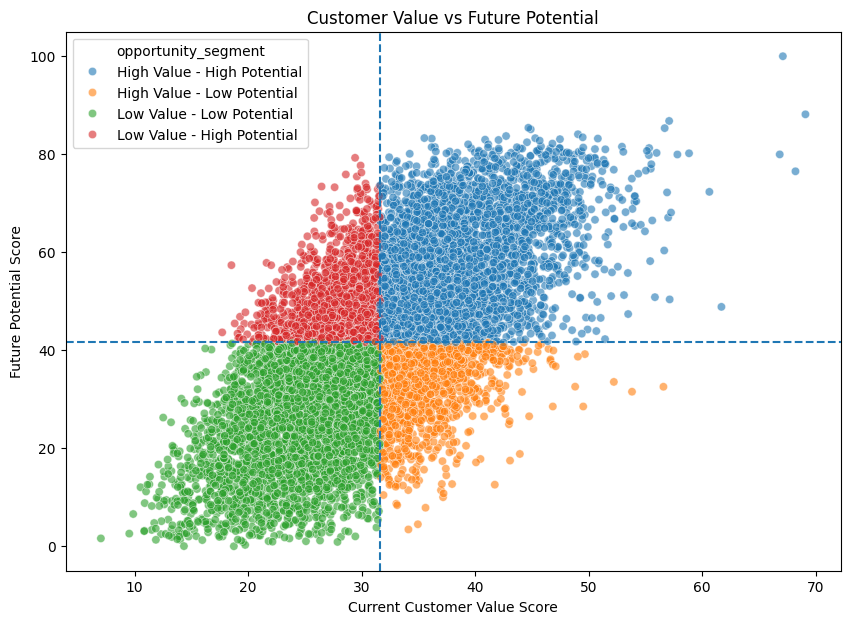

In [45]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="calculated_customer_value_score",
    y="potential_score",
    hue="opportunity_segment",
    alpha=0.6
)

plt.axvline(
    value_threshold,
    linestyle="--"
)

plt.axhline(
    potential_threshold,
    linestyle="--"
)

plt.title("Customer Value vs Future Potential")
plt.xlabel("Current Customer Value Score")
plt.ylabel("Future Potential Score")

plt.show()

## 7. K-Means clustering
12 raw features → StandardScaler (so large rupee values don't dominate) → K-Means with k = 4 (one cluster per business tier).

In [48]:
clustering_features = [
    "age",
    "annual_income",
    "avg_balance",
    "monthly_transactions",
    "monthly_spend",
    "credit_score",
    "loan_amount",
    "investment_value",
    "products_used",
    "mobile_app_logins",
    "years_with_bank",
    "complaints"
]

X_cluster = df[clustering_features]

print("Shape:", X_cluster.shape)

Shape: (10000, 12)


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

print(X_scaled.shape)

(10000, 12)


In [50]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X_scaled)

df["cluster"].value_counts().sort_index()

,count
cluster,
0,3220
1,1468
2,1945
3,3367


In [51]:
cluster_profile = df.groupby("cluster")[clustering_features].mean().round(2)

cluster_profile

,age,annual_income,avg_balance,monthly_transactions,monthly_spend,credit_score,loan_amount,investment_value,products_used,mobile_app_logins,years_with_bank,complaints
cluster,,,,,,,,,,,,
0,46.93,776303.51,948623.05,136.12,40532.19,709.36,365148.56,730999.74,5.81,26.91,11.81,0.21
1,45.23,2056248.47,2960753.87,130.35,124423.22,717.62,338102.29,2363709.84,4.00,30.09,12.08,0.49
2,45.80,780726.49,959857.89,132.55,40000.86,737.82,293075.27,752138.60,4.24,36.17,11.84,1.47
3,44.44,768357.34,942419.53,121.30,39741.56,719.69,327466.89,720290.90,2.20,27.70,12.17,0.23


In [52]:
cluster_profile = df.groupby("cluster")[clustering_features].mean().round(2)

cluster_profile.insert(
    0,
    "customer_count",
    df["cluster"].value_counts().sort_index()
)

cluster_profile

,customer_count,age,annual_income,avg_balance,monthly_transactions,monthly_spend,credit_score,loan_amount,investment_value,products_used,mobile_app_logins,years_with_bank,complaints
cluster,,,,,,,,,,,,,
0,3220,46.93,776303.51,948623.05,136.12,40532.19,709.36,365148.56,730999.74,5.81,26.91,11.81,0.21
1,1468,45.23,2056248.47,2960753.87,130.35,124423.22,717.62,338102.29,2363709.84,4.00,30.09,12.08,0.49
2,1945,45.80,780726.49,959857.89,132.55,40000.86,737.82,293075.27,752138.60,4.24,36.17,11.84,1.47
3,3367,44.44,768357.34,942419.53,121.30,39741.56,719.69,327466.89,720290.90,2.20,27.70,12.17,0.23


In [53]:
pd.crosstab(
    df["cluster"],
    df["segment"],
    normalize="index"
).round(3) * 100

segment,Gold,Premium,Silver,Standard
cluster,,,,
0,40.7,0.7,50.1,8.5
1,10.1,71.0,7.7,11.1
2,55.4,1.1,20.6,23.0
3,22.4,0.5,8.7,68.4


## 8. Compare K-Means clusters with the bank's existing segments
Map each cluster to the segment it overlaps most and measure agreement.

In [54]:
cluster_to_segment = {
    0: "Silver",
    1: "Premium",
    2: "Gold",
    3: "Standard"
}
df["kmeans_segment"] = df["cluster"].map(cluster_to_segment)

df["kmeans_segment"].value_counts()

,count
kmeans_segment,
Standard,3367
Silver,3220
Gold,1945
Premium,1468


In [55]:
comparison = pd.crosstab(
    df["segment"],
    df["kmeans_segment"]
)

comparison

kmeans_segment,Gold,Premium,Silver,Standard
segment,,,,
Gold,1077,149,1311,753
Premium,21,1043,22,18
Silver,400,113,1614,293
Standard,447,163,273,2303


In [56]:
comparison_pct = pd.crosstab(
    df["segment"],
    df["kmeans_segment"],
    normalize="index"
).round(3) * 100

comparison_pct

kmeans_segment,Gold,Premium,Silver,Standard
segment,,,,
Gold,32.7,4.5,39.8,22.9
Premium,1.9,94.5,2.0,1.6
Silver,16.5,4.7,66.7,12.1
Standard,14.0,5.1,8.6,72.3


In [57]:
agreement = (
    df["segment"] == df["kmeans_segment"]
).mean() * 100

print(f"Overall segment agreement: {agreement:.2f}%")

Overall segment agreement: 60.37%


In [58]:
segment_agreement = (
    df.groupby("segment")
      .apply(lambda x: (x["segment"] == x["kmeans_segment"]).mean() * 100)
      .round(2)
)

segment_agreement

/tmp/ipykernel_3088/394615848.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x["segment"] == x["kmeans_segment"]).mean() * 100)


,0
segment,
Gold,32.74
Premium,94.47
Silver,66.69
Standard,72.28


## 9. Opportunity targeting
Focus on **Low Value – High Potential** customers and rank them by potential score into High / Medium / Low priority.

In [63]:
opportunity_summary = (
    df["opportunity_segment"]
    .value_counts()
    .to_frame("customer_count")
)

opportunity_summary["percentage"] = (
    opportunity_summary["customer_count"]
    / len(df) * 100
).round(2)

opportunity_summary

,customer_count,percentage
opportunity_segment,,
High Value - High Potential,3662,36.62
Low Value - Low Potential,3662,36.62
High Value - Low Potential,1338,13.38
Low Value - High Potential,1338,13.38


In [64]:
high_potential = df[
    df["opportunity_segment"] == "Low Value - High Potential"
]

high_potential_profile = (
    high_potential[
        [
            "annual_income",
            "avg_balance",
            "monthly_transactions",
            "monthly_spend",
            "credit_score",
            "loan_amount",
            "investment_value",
            "products_used",
            "mobile_app_logins",
            "years_with_bank",
            "complaints"
        ]
    ]
    .mean()
    .round(2)
)

high_potential_profile

,0
annual_income,784420.01
avg_balance,926757.94
monthly_transactions,65.13
monthly_spend,39712.38
credit_score,702.32
loan_amount,258156.50
investment_value,783959.26
products_used,5.16
mobile_app_logins,31.95
years_with_bank,9.74


In [65]:
high_potential["kmeans_segment"].value_counts()

,count
kmeans_segment,
Silver,700
Gold,321
Standard,235
Premium,82


In [66]:
top_opportunities = (
    df[df["opportunity_segment"] == "Low Value - High Potential"]
    .sort_values("potential_score", ascending=False)
)

top_opportunities[
    [
        "customer_id",
        "kmeans_segment",
        "potential_score",
        "calculated_customer_value_score",
        "annual_income",
        "avg_balance",
        "monthly_spend",
        "investment_value",
        "products_used",
        "mobile_app_logins"
    ]
].head(20)

,customer_id,kmeans_segment,potential_score,calculated_customer_value_score,annual_income,avg_balance,monthly_spend,investment_value,products_used,mobile_app_logins
1894,C101895,Gold,79.270146,29.425752,427175,675333,5932,704684,7,57
4462,C104463,Silver,77.686144,29.912167,339344,644552,20237,587737,7,55
7906,C107907,Silver,76.257184,29.979221,712905,1518977,8947,546329,7,53
6589,C106590,Gold,75.870155,28.609019,814316,142567,11401,1612813,6,59
566,C100567,Silver,75.455277,29.578732,214028,169256,15992,155624,7,53
2805,C102806,Gold,74.021869,30.347573,851773,1881240,49549,439454,7,50
5033,C105034,Gold,73.446584,31.566477,454056,796162,38479,159164,7,50
7426,C107427,Silver,73.406231,26.473235,692623,573294,16956,794313,7,48
4772,C104773,Silver,73.272099,30.420285,494111,712616,4813,728961,7,48
3919,C103920,Silver,73.263655,27.622881,383706,150696,15984,724847,7,48


In [67]:
q75 = top_opportunities["potential_score"].quantile(0.75)
q50 = top_opportunities["potential_score"].quantile(0.50)

df["opportunity_priority"] = "Not Targeted"

mask = df["opportunity_segment"] == "Low Value - High Potential"

df.loc[
    mask & (df["potential_score"] >= q75),
    "opportunity_priority"
] = "High"

df.loc[
    mask & (df["potential_score"] >= q50) &
    (df["potential_score"] < q75),
    "opportunity_priority"
] = "Medium"

df.loc[
    mask & (df["potential_score"] < q50),
    "opportunity_priority"
] = "Low"

df["opportunity_priority"].value_counts()

,count
opportunity_priority,
Not Targeted,8662
Low,669
High,335
Medium,334


In [68]:
priority_profile = (
    df[df["opportunity_priority"] != "Not Targeted"]
    .groupby("opportunity_priority")[
        [
            "potential_score",
            "calculated_customer_value_score",
            "annual_income",
            "avg_balance",
            "monthly_transactions",
            "monthly_spend",
            "credit_score",
            "investment_value",
            "products_used",
            "mobile_app_logins",
            "years_with_bank",
            "complaints"
        ]
    ]
    .mean()
    .round(2)
)

priority_profile

,potential_score,calculated_customer_value_score,annual_income,avg_balance,monthly_transactions,monthly_spend,credit_score,investment_value,products_used,mobile_app_logins,years_with_bank,complaints
opportunity_priority,,,,,,,,,,,,
High,60.67,29.04,758654.89,864438.77,50.23,37142.04,690.68,770342.67,6.00,38.96,8.58,0.50
Low,44.97,27.27,798431.51,972774.13,74.49,41530.60,710.33,779180.95,4.78,27.60,10.08,0.52
Medium,51.25,27.89,782197.34,897093.54,61.35,38648.52,697.94,807187.55,5.10,33.66,10.21,0.52


In [69]:
priority_segment = pd.crosstab(
    df[df["opportunity_priority"] != "Not Targeted"]["opportunity_priority"],
    df[df["opportunity_priority"] != "Not Targeted"]["kmeans_segment"]
)

priority_segment

kmeans_segment,Gold,Premium,Silver,Standard
opportunity_priority,,,,
High,90,11,219,15
Low,152,49,317,151
Medium,79,22,164,69


In [70]:
priority_summary = (
    df[df["opportunity_priority"] != "Not Targeted"]
    .groupby(["opportunity_priority", "kmeans_segment"])
    .size()
    .reset_index(name="customer_count")
    .sort_values(
        ["opportunity_priority", "customer_count"],
        ascending=[True, False]
    )
)

priority_summary

,opportunity_priority,kmeans_segment,customer_count
2,High,Silver,219
0,High,Gold,90
3,High,Standard,15
1,High,Premium,11
6,Low,Silver,317
4,Low,Gold,152
7,Low,Standard,151
5,Low,Premium,49
10,Medium,Silver,164
8,Medium,Gold,79


In [71]:
high_priority = df[
    df["opportunity_priority"] == "High"
]

high_priority.groupby("kmeans_segment")[
    [
        "annual_income",
        "avg_balance",
        "monthly_spend",
        "investment_value",
        "products_used",
        "mobile_app_logins",
        "credit_score"
    ]
].mean().round(2)

,annual_income,avg_balance,monthly_spend,investment_value,products_used,mobile_app_logins,credit_score
kmeans_segment,,,,,,,
Gold,798788.30,889271.69,37899.58,699477.23,5.51,44.50,702.79
Premium,1749028.55,2391149.55,87638.45,2583523.00,5.55,36.18,668.27
Silver,691203.38,776443.31,34409.85,715058.19,6.36,35.76,685.79
Standard,776372.47,880587.20,35456.00,673023.13,4.00,54.40,705.80


## 10. Recommended actions
Assign a business action to each prioritised customer based on priority and cluster.

In [72]:
def recommend_action(row):

    if row["opportunity_priority"] == "High":
        if row["kmeans_segment"] == "Silver":
            return "Relationship Deepening / Upgrade"
        elif row["kmeans_segment"] == "Gold":
            return "Premium Upgrade / Wealth Products"
        elif row["kmeans_segment"] == "Standard":
            return "Cross-sell / Engagement"
        elif row["kmeans_segment"] == "Premium":
            return "Retention / Wealth Management"

    elif row["opportunity_priority"] == "Medium":
        return "Targeted Cross-sell"

    elif row["opportunity_priority"] == "Low":
        return "Digital Engagement"

    return "No Immediate Action"


df["recommended_action"] = df.apply(recommend_action, axis=1)

In [73]:
action_summary = (
    df[df["recommended_action"] != "No Immediate Action"]
    .groupby("recommended_action")
    .size()
    .reset_index(name="customer_count")
    .sort_values("customer_count", ascending=False)
)

action_summary

,recommended_action,customer_count
1,Digital Engagement,669
5,Targeted Cross-sell,334
3,Relationship Deepening / Upgrade,219
2,Premium Upgrade / Wealth Products,90
0,Cross-sell / Engagement,15
4,Retention / Wealth Management,11
